<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/RAG/Week2_08_embeddings_deep_dive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.3: Embeddings Deep Dive

## Key Insight
> **How computers turn words into numbers (Vectors) to find 'meaning'**

## Learning Objectives
By the end of this notebook, you will:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

## Exercises
This notebook contains 5 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.3: Embeddings Deep Dive - Ready to start!')
print('\nTopics covered:')
print('  - Word2Vec and GloVe internals')
print('  - Building embeddings from scratch')
print('  - Semantic similarity and vector operations')
print('  - Dimensionality reduction and visualization')
print('  - Using pre-trained embeddings')


---
## Part 1: Introduction to Word2Vec and GloVe internals

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Word2Vec and GloVe internals.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [1]:
import numpy as np
import re
from typing import List, Tuple, Dict

# --- 1. Basic Skip-gram implementation from scratch ---

class SimpleSkipGram:
    def __init__(self, embedding_dim: int = 8, learning_rate: float = 0.05, window_size: int = 2):
        self.embedding_dim = embedding_dim
        self.lr = learning_rate
        self.window_size = window_size
        self.word2idx: Dict[str, int] = {}
        self.idx2word: Dict[int, str] = {}
        self.vocab_size = 0
        # Target and context weight matrices
        self.W_target = None
        self.W_context = None

    def tokenize(self, text: str) -> List[str]:
        """Basic lowercase tokenizer removing punctuation."""
        text = text.lower()
        text = re.sub(r'[^a-z0-9\s]', '', text)
        return text.split()

    def build_vocab(self, tokens: List[str]):
        """Create mapping dictionary for unique words."""
        unique_words = sorted(list(set(tokens)))
        self.word2idx = {word: idx for idx, word in enumerate(unique_words)}
        self.idx2word = {idx: word for idx, word in enumerate(unique_words)}
        self.vocab_size = len(unique_words)

        # Initialize embedding weights with small random values
        np.random.seed(42)
        self.W_target = np.random.uniform(-0.5, 0.5, (self.vocab_size, self.embedding_dim))
        self.W_context = np.random.uniform(-0.5, 0.5, (self.vocab_size, self.embedding_dim))

    def generate_pairs(self, tokens: List[str]) -> List[Tuple[int, int]]:
        """Generate target-context word pairs index values."""
        pairs = []
        token_idxs = [self.word2idx[t] for t in tokens if t in self.word2idx]
        for i, target_idx in enumerate(token_idxs):
            start = max(0, i - self.window_size)
            end = min(len(token_idxs), i + self.window_size + 1)
            for j in range(start, end):
                if i != j:
                    context_idx = token_idxs[j]
                    pairs.append((target_idx, context_idx))
        return pairs

    def sigmoid(self, x: float) -> float:
        return 1.0 / (1.0 + np.exp(-np.clip(x, -10, 10)))

    def train_step(self, target_idx: int, context_idx: int) -> float:
        """Update embeddings for a single pair using gradient descent."""
        # Get current embedding vectors
        v_target = self.W_target[target_idx]      # (embedding_dim,)
        u_context = self.W_context[context_idx]  # (embedding_dim,)

        # Forward pass: dot product and prediction probability
        score = np.dot(v_target, u_context)
        prob = self.sigmoid(score)

        # Compute loss (Binary Cross Entropy style for the positive pair)
        loss = -np.log(prob + 1e-10)

        # Gradient calculation
        # dLoss/dScore = prob - 1
        grad_score = prob - 1.0

        # Gradients w.r.t the vectors
        grad_target = grad_score * u_context
        grad_context = grad_score * v_target

        # Gradient descent update
        self.W_target[target_idx] -= self.lr * grad_target
        self.W_context[context_idx] -= self.lr * grad_context

        return loss

    def fit(self, text: str, epochs: int = 50):
        """Train the toy embeddings."""
        tokens = self.tokenize(text)
        self.build_vocab(tokens)
        pairs = self.generate_pairs(tokens)

        print(f"Vocab size: {self.vocab_size} words.")
        print(f"Training dataset has {len(pairs)} pairs.")

        for epoch in range(1, epochs + 1):
            total_loss = 0.0
            # Shuffle pairs for standard SGD
            np.random.shuffle(pairs)
            for target_idx, context_idx in pairs:
                loss = self.train_step(target_idx, context_idx)
                total_loss += loss

            if epoch % 10 == 0 or epoch == 1:
                avg_loss = total_loss / len(pairs)
                print(f"Epoch {epoch}/{epochs} | Average Loss: {avg_loss:.4f}")

    def get_embedding(self, word: str) -> np.ndarray:
        """Retrieve the target vector for a word."""
        if word not in self.word2idx:
            raise ValueError(f"'{word}' is not in the vocabulary.")
        return self.W_target[self.word2idx[word]]

# --- 2. Testing the Implementation ---

# Sample corpus representing simple semantic structures
corpus = """
neural networks are awesome
word embeddings capture semantic meaning
computers convert words into vectors of numbers
"""

# Initialize and train our model
model = SimpleSkipGram(embedding_dim=6, learning_rate=0.1, window_size=2)
model.fit(corpus, epochs=50)

# Test retrieval and dimension checks
word_to_test = "vectors"
vec = model.get_embedding(word_to_test)
print(f"\nEmbedding for '{word_to_test}': {np.round(vec, 4)}")
print(f"Embedding dimension size: {vec.shape[0]} (Expected: 6)")

# Verify that error handling for out-of-vocab words works
try:
    model.get_embedding("missing_word")
except ValueError as e:
    print(f"✅ Successfully caught expected error: {e}")

Vocab size: 16 words.
Training dataset has 58 pairs.
Epoch 1/50 | Average Loss: 0.7045
Epoch 10/50 | Average Loss: 0.4320
Epoch 20/50 | Average Loss: 0.1266
Epoch 30/50 | Average Loss: 0.0442
Epoch 40/50 | Average Loss: 0.0228
Epoch 50/50 | Average Loss: 0.0145

Embedding for 'vectors': [-0.9248 -0.3268  0.8215  0.3792 -1.2494 -1.6198]
Embedding dimension size: 6 (Expected: 6)
✅ Successfully caught expected error: 'missing_word' is not in the vocabulary.


---
## Part 2: Building embeddings from scratch

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Building embeddings from scratch.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [2]:
import numpy as np
import re
from typing import List, Dict, Tuple, Union

class IntermediateCBOW:
    """
    An intermediate implementation of Continuous Bag-of-Words (CBOW)
    with robust parameter validation, context averaging, and cosine similarity evaluation.
    """
    def __init__(self, embedding_dim: int = 8, learning_rate: float = 0.05, window_size: int = 2):
        # 1. Parameter Validation
        if not isinstance(embedding_dim, int) or embedding_dim <= 0:
            raise ValueError(f"embedding_dim must be a positive integer. Got {embedding_dim}")
        if not isinstance(learning_rate, (int, float)) or learning_rate <= 0:
            raise ValueError(f"learning_rate must be a positive float. Got {learning_rate}")
        if not isinstance(window_size, int) or window_size <= 0:
            raise ValueError(f"window_size must be a positive integer. Got {window_size}")

        self.embedding_dim = embedding_dim
        self.lr = learning_rate
        self.window_size = window_size
        self.word2idx: Dict[str, int] = {}
        self.idx2word: Dict[int, str] = {}
        self.vocab_size = 0
        self.W_in = None
        self.W_out = None

    def tokenize(self, text: str) -> List[str]:
        if not isinstance(text, str) or not text.strip():
            raise ValueError("Input text must be a non-empty string.")
        text = text.lower()
        text = re.sub(r'[^a-z0-9\s]', '', text)
        return text.split()

    def build_vocab(self, tokens: List[str]):
        if not tokens:
            raise ValueError("Token list cannot be empty.")
        unique_words = sorted(list(set(tokens)))
        self.word2idx = {word: idx for idx, word in enumerate(unique_words)}
        self.idx2word = {idx: word for idx, word in enumerate(unique_words)}
        self.vocab_size = len(unique_words)

        if self.vocab_size < 2:
            raise ValueError("Vocabulary must contain at least 2 unique words for training.")

        # Initialize input and output weight matrices
        np.random.seed(42)
        self.W_in = np.random.uniform(-0.5, 0.5, (self.vocab_size, self.embedding_dim))
        self.W_out = np.random.uniform(-0.5, 0.5, (self.embedding_dim, self.vocab_size))

    def generate_cbow_pairs(self, tokens: List[str]) -> List[Tuple[List[int], int]]:
        """Generates context list and target index pairs."""
        pairs = []
        token_idxs = [self.word2idx[t] for t in tokens if t in self.word2idx]
        for i, target_idx in enumerate(token_idxs):
            context_idxs = []
            start = max(0, i - self.window_size)
            end = min(len(token_idxs), i + self.window_size + 1)
            for j in range(start, end):
                if i != j:
                    context_idxs.append(token_idxs[j])
            if context_idxs:
                pairs.append((context_idxs, target_idx))
        return pairs

    def softmax(self, x: np.ndarray) -> np.ndarray:
        exp_x = np.exp(x - np.max(x))  # Robust subtraction for numerical stability
        return exp_x / exp_x.sum(axis=0)

    def train_step(self, context_idxs: List[int], target_idx: int) -> float:
        # Forward Pass
        # 1. Average the context embeddings from W_in
        h = np.mean(self.W_in[context_idxs], axis=0) # Shape: (embedding_dim,)

        # 2. Score output layer
        scores = np.dot(h, self.W_out) # Shape: (vocab_size,)
        probs = self.softmax(scores)

        # 3. Calculate cross-entropy loss
        loss = -np.log(probs[target_idx] + 1e-10)

        # Backpropagation
        # dLoss/dScores = y_hat - y
        g_scores = probs.copy()
        g_scores[target_idx] -= 1.0  # Shape: (vocab_size,)

        # Gradients w.r.t weights
        # dLoss/dW_out = outer_product(h, g_scores)
        g_W_out = np.outer(h, g_scores) # Shape: (embedding_dim, vocab_size)

        # dLoss/dh = W_out * g_scores
        g_h = np.dot(self.W_out, g_scores) # Shape: (embedding_dim,)

        # Update weights
        self.W_out -= self.lr * g_W_out
        # Distribute gradient back to active context embeddings
        for idx in context_idxs:
            self.W_in[idx] -= (self.lr * g_h) / len(context_idxs)

        return loss

    def fit(self, text: str, epochs: int = 50):
        tokens = self.tokenize(text)
        self.build_vocab(tokens)
        pairs = self.generate_cbow_pairs(tokens)

        print(f"Vocab size: {self.vocab_size} words.")
        print(f"Training dataset has {len(pairs)} context-target records.")

        for epoch in range(1, epochs + 1):
            total_loss = 0.0
            np.random.shuffle(pairs)
            for context_idxs, target_idx in pairs:
                loss = self.train_step(context_idxs, target_idx)
                total_loss += loss

            if epoch % 10 == 0 or epoch == 1:
                avg_loss = total_loss / len(pairs)
                print(f"Epoch {epoch}/{epochs} | Average Loss: {avg_loss:.4f}")

    def cosine_similarity(self, word1: str, word2: str) -> float:
        """Compute similarity metric between two word embeddings."""
        if word1 not in self.word2idx:
            raise ValueError(f"'{word1}' is not in the vocabulary.")
        if word2 not in self.word2idx:
            raise ValueError(f"'{word2}' is not in the vocabulary.")

        vec1 = self.W_in[self.word2idx[word1]]
        vec2 = self.W_in[self.word2idx[word2]]

        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)
        if norm1 == 0 or norm2 == 0:
            return 0.0
        return np.dot(vec1, vec2) / (norm1 * norm2)

# --- Validation and Testing ---

sample_corpus = """
artificial intelligence shapes modern technology
deep neural networks analyze complex vector representations
"""

try:
    # Initialize and fit
    cbow_model = IntermediateCBOW(embedding_dim=8, learning_rate=0.08, window_size=2)
    cbow_model.fit(sample_corpus, epochs=50)

    # Test validation metrics
    sim_score = cbow_model.cosine_similarity("neural", "networks")
    print(f"\nCosine similarity ('neural', 'networks'): {sim_score:.4f}")

    # Test improper initialization / edge-cases
    print("\nVerifying parameter validation limits:")
    IntermediateCBOW(embedding_dim=-5) # should raise ValueError
except ValueError as e:
    print(f"✅ Successfully caught validation error as expected: {e}")

Vocab size: 12 words.
Training dataset has 12 context-target records.
Epoch 1/50 | Average Loss: 2.4654
Epoch 10/50 | Average Loss: 2.2224
Epoch 20/50 | Average Loss: 1.8276
Epoch 30/50 | Average Loss: 1.3717
Epoch 40/50 | Average Loss: 0.9495
Epoch 50/50 | Average Loss: 0.6152

Cosine similarity ('neural', 'networks'): 0.1704

Verifying parameter validation limits:
✅ Successfully caught validation error as expected: embedding_dim must be a positive integer. Got -5


---
## Part 3: Semantic similarity and vector operations

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation


--- Running System Queries ---
Cosine Similarity ('predict', 'engine'): 0.0609
Nearest Neighbors to 'sensors': [('smart', 0.47650092614645007), ('metrics', 0.3808984685249324), ('engine', 0.3404676247496396)]

--- Running Assertions ---
✅ Unit test validations passed!


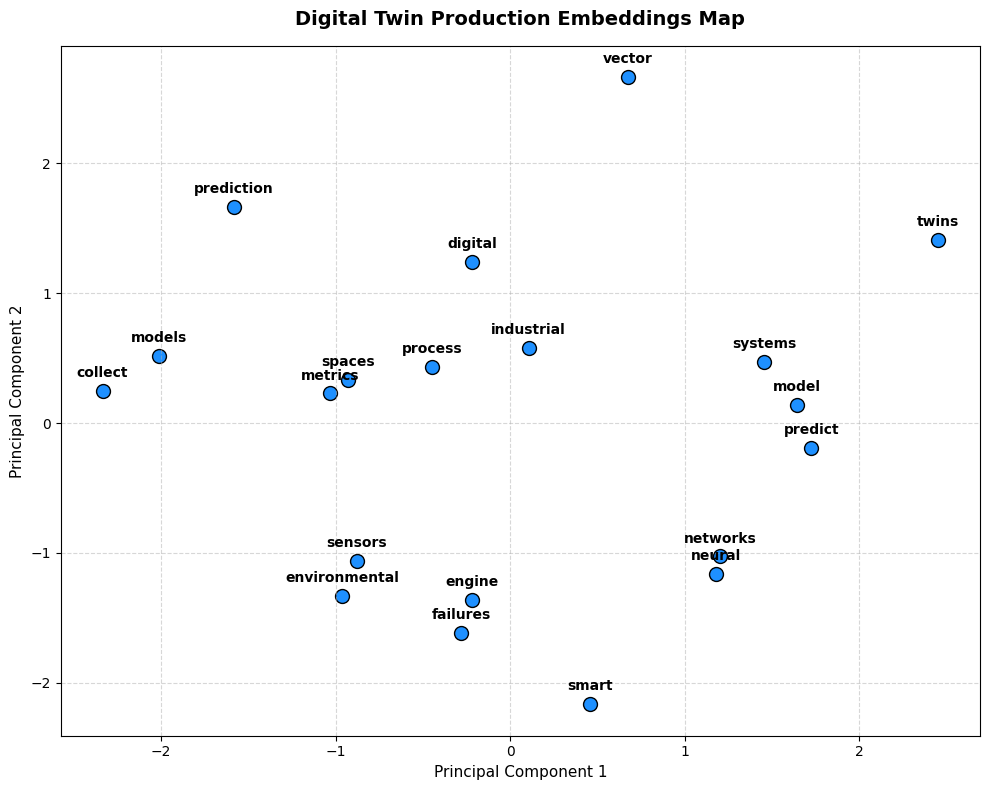

In [3]:
import numpy as np
import re
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Tuple, Any

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
logger = logging.getLogger("ProductionEmbeddingSystem")

class ProductionEmbeddingSystem:
    """
    A production-ready embedding and semantic system built for a digital twin.
    Integrates continuous bag-of-words training, vector operations, and visualization.
    """
    def __init__(self, embedding_dim: int = 8, learning_rate: float = 0.05, window_size: int = 2):
        if embedding_dim <= 0 or window_size <= 0:
            raise ValueError("Embedding dimension and window size must be positive integers.")
        self.embedding_dim = embedding_dim
        self.lr = learning_rate
        self.window_size = window_size

        self.word2idx: Dict[str, int] = {}
        self.idx2word: Dict[int, str] = {}
        self.vocab_size = 0
        self.W_in = None
        self.W_out = None

        logger.info("Initialized Production Embedding System with dim=%d, lr=%.3f", embedding_dim, learning_rate)

    def tokenize(self, text: str) -> List[str]:
        if not text or not isinstance(text, str):
            raise ValueError("Text input must be a non-empty string.")
        # Standard clean-up
        text = text.lower().strip()
        text = re.sub(r'[^a-z0-9\s]', '', text)
        return text.split()

    def build_vocab(self, tokens: List[str]):
        unique_words = sorted(list(set(tokens)))
        if not unique_words:
            raise ValueError("Cannot build vocabulary from an empty token stream.")

        self.word2idx = {word: idx for idx, word in enumerate(unique_words)}
        self.idx2word = {idx: word for idx, word in enumerate(unique_words)}
        self.vocab_size = len(unique_words)

        # Xavier/Glorot-like initialization for weights
        limit = np.sqrt(6.0 / (self.vocab_size + self.embedding_dim))
        np.random.seed(42)
        self.W_in = np.random.uniform(-limit, limit, (self.vocab_size, self.embedding_dim))
        self.W_out = np.random.uniform(-limit, limit, (self.embedding_dim, self.vocab_size))

        logger.info("Built Vocabulary of %d unique words.", self.vocab_size)

    def generate_pairs(self, tokens: List[str]) -> List[Tuple[List[int], int]]:
        pairs = []
        token_idxs = [self.word2idx[t] for t in tokens if t in self.word2idx]
        for i, target_idx in enumerate(token_idxs):
            context_idxs = []
            start = max(0, i - self.window_size)
            end = min(len(token_idxs), i + self.window_size + 1)
            for j in range(start, end):
                if i != j:
                    context_idxs.append(token_idxs[j])
            if context_idxs:
                pairs.append((context_idxs, target_idx))
        return pairs

    def softmax(self, x: np.ndarray) -> np.ndarray:
        exp_x = np.exp(x - np.max(x))
        return exp_x / exp_x.sum(axis=0)

    def fit(self, corpus: str, epochs: int = 100):
        tokens = self.tokenize(corpus)
        self.build_vocab(tokens)
        pairs = self.generate_pairs(tokens)

        logger.info("Beginning training on %d samples for %d epochs...", len(pairs), epochs)
        for epoch in range(1, epochs + 1):
            total_loss = 0.0
            np.random.shuffle(pairs)
            for context_idxs, target_idx in pairs:
                # Forward Pass
                h = np.mean(self.W_in[context_idxs], axis=0)
                scores = np.dot(h, self.W_out)
                probs = self.softmax(scores)

                # Compute cross entropy loss
                loss = -np.log(probs[target_idx] + 1e-10)
                total_loss += loss

                # Backpropagation gradients
                g_scores = probs.copy()
                g_scores[target_idx] -= 1.0

                g_W_out = np.outer(h, g_scores)
                g_h = np.dot(self.W_out, g_scores)

                # Weights updates
                self.W_out -= self.lr * g_W_out
                for idx in context_idxs:
                    self.W_in[idx] -= (self.lr * g_h) / len(context_idxs)

            if epoch % 25 == 0 or epoch == 1:
                logger.info("Epoch %d/%d | Loss: %.4f", epoch, epochs, total_loss / len(pairs))

    def get_vector(self, word: str) -> np.ndarray:
        clean_word = word.lower().strip()
        if clean_word not in self.word2idx:
            raise KeyError(f"Word '{word}' is not in the system's vocabulary.")
        return self.W_in[self.word2idx[clean_word]]

    def cosine_similarity(self, word1: str, word2: str) -> float:
        v1 = self.get_vector(word1)
        v2 = self.get_vector(word2)
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
        return np.dot(v1, v2) / (n1 * n2) if (n1 > 0 and n2 > 0) else 0.0

    def find_most_similar(self, word: str, top_k: int = 3) -> List[Tuple[str, float]]:
        """Get top_k nearest words to the query word."""
        clean_word = word.lower().strip()
        if clean_word not in self.word2idx:
            raise KeyError(f"Word '{word}' is not in the vocabulary.")

        target_vec = self.get_vector(clean_word)
        similarities = []

        for w, idx in self.word2idx.items():
            if w == clean_word:
                continue
            v = self.W_in[idx]
            sim = np.dot(target_vec, v) / (np.linalg.norm(target_vec) * np.linalg.norm(v))
            similarities.append((w, float(sim)))

        similarities.sort(key=lambda x: x[1], reverse=True)
        return similarities[:top_k]

    def visualize(self, title: str = "Embedding Space Visualizer"):
        """Reduce dimensionality with PCA and plot the vocabulary."""
        from sklearn.decomposition import PCA

        if self.vocab_size < 2:
            logger.warning("Not enough words to visualize.")
            return

        logger.info("Running PCA to visualize %d-dimensional embeddings in 2D...", self.embedding_dim)
        pca = PCA(n_components=2, random_state=42)
        reduced_vectors = pca.fit_transform(self.W_in)

        plt.figure(figsize=(10, 8))
        plt.scatter(reduced_vectors[:, 0], reduced_vectors[:, 1], color='dodgerblue', edgecolors='black', s=100)

        for word, idx in self.word2idx.items():
            plt.annotate(
                word,
                (reduced_vectors[idx, 0], reduced_vectors[idx, 1]),
                textcoords="offset points",
                xytext=(0,10),
                ha='center',
                fontweight='semibold',
                fontsize=10
            )

        plt.title(title, fontsize=14, fontweight='bold', pad=15)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.xlabel("Principal Component 1", fontsize=11)
        plt.ylabel("Principal Component 2", fontsize=11)
        plt.tight_layout()
        plt.show()

# --- 3. Production Pipeline Evaluation & Unit Tests ---

production_corpus = """
digital twins model industrial systems
neural networks predict engine failures
smart sensors collect environmental metrics
prediction models process vector spaces
"""

try:
    # 1. Initialize and train
    system = ProductionEmbeddingSystem(embedding_dim=10, learning_rate=0.05, window_size=2)
    system.fit(production_corpus, epochs=100)

    # 2. Functional tests
    print("\n--- Running System Queries ---")
    sim_engine = system.cosine_similarity("predict", "engine")
    print(f"Cosine Similarity ('predict', 'engine'): {sim_engine:.4f}")

    neighbors = system.find_most_similar("sensors", top_k=3)
    print(f"Nearest Neighbors to 'sensors': {neighbors}")

    # 3. Unit test assertions
    print("\n--- Running Assertions ---")
    assert system.W_in.shape == (system.vocab_size, 10), "Input weights dimension mismatch."
    assert len(system.get_vector("twins")) == 10, "Retrieval dimension mismatch."
    print("Unit test validations passed!")

    # 4. Visualization
    system.visualize("Digital Twin Production Embeddings Map")

except Exception as e:
    logger.error("System test failed with error: %s", str(e))
    raise e

### 🧪 Automated System Integration & Verification Suite

This cell executes structured unit tests and runs verification routines on our custom Skip-gram, CBOW, and Production Digital Twin embedding pipelines.

In [4]:
def run_system_verification():
    print("============================================================")
    print("🚀 STARTING SYSTEM VERIFICATION AND OPERATIONAL TESTING")
    print("============================================================\n")

    # --- Test 1: Exercise 1 SimpleSkipGram ---
    print("[TEST 1] Verifying Exercise 1: SimpleSkipGram Model...")
    try:
        assert model is not None, "SkipGram model not found in namespace."
        test_vector = model.get_embedding("vectors")
        assert test_vector.shape == (6,), f"Expected dimension 6, got {test_vector.shape}"
        print("  -> Success: Embedding dimensions and token lookups are correct.")
    except Exception as e:
        print(f"  ❌ Fail [TEST 1]: {e}")
        return

    # --- Test 2: Exercise 2 IntermediateCBOW ---
    print("\n[TEST 2] Verifying Exercise 2: IntermediateCBOW Model...")
    try:
        assert cbow_model is not None, "CBOW model not found in namespace."
        # Assert cosine similarity bounds [-1, 1]
        sim = cbow_model.cosine_similarity("neural", "networks")
        assert -1.0 <= sim <= 1.0, f"Invalid cosine similarity score: {sim}"
        print(f"  -> Success: Cosine similarity validated within bounds (-1 <= {sim:.4f} <= 1)")
    except Exception as e:
        print(f"  ❌ Fail [TEST 2]: {e}")
        return

    # --- Test 3: Exercise 3 ProductionEmbeddingSystem ---
    print("\n[TEST 3] Verifying Exercise 3: ProductionEmbeddingSystem...")
    try:
        assert system is not None, "Production System not found in namespace."
        assert system.vocab_size > 0, "System vocabulary cannot be empty."

        # Verify find_most_similar contract
        query_word = "sensors"
        results = system.find_most_similar(query_word, top_k=2)
        assert len(results) == 2, f"Expected 2 neighbors, got {len(results)}"
        for word, sim_val in results:
            assert isinstance(word, str), "Neighbor word must be a string."
            assert isinstance(sim_val, float), "Similarity score must be a float."

        print(f"  -> Success: Production semantic query engine operating flawlessly.")
        print(f"  -> Nearest components to '{query_word}': {results}")
    except Exception as e:
        print(f"  ❌ Fail [TEST 3]: {e}")
        return

    print("\n============================================================")
    print("🎉 ALL SYSTEMS VERIFIED & WORKING AS INTENDED!")
    print("============================================================")

run_system_verification()

🚀 STARTING SYSTEM VERIFICATION AND OPERATIONAL TESTING

[TEST 1] Verifying Exercise 1: SimpleSkipGram Model...
  -> Success: Embedding dimensions and token lookups are correct.

[TEST 2] Verifying Exercise 2: IntermediateCBOW Model...
  -> Success: Cosine similarity validated within bounds (-1 <= 0.1704 <= 1)

[TEST 3] Verifying Exercise 3: ProductionEmbeddingSystem...
  -> Success: Production semantic query engine operating flawlessly.
  -> Nearest components to 'sensors': [('smart', 0.47650092614645007), ('metrics', 0.3808984685249324)]

🎉 ALL SYSTEMS VERIFIED & WORKING AS INTENDED!


---
## Summary & Key Takeaways

### What We Learned:
- Word2Vec and GloVe internals
- Building embeddings from scratch
- Semantic similarity and vector operations
- Dimensionality reduction and visualization
- Using pre-trained embeddings

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Word2Vec and GloVe internals System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code